# Apple: option valuation and downside protection from observed prices
**Research question:** How sensitive is the estimated cost of protecting an Apple position to the volatility estimation window, and does Monte Carlo reproduce Black–Scholes–Merton?

Use observed stock prices to calibrate volatility and value a hypothetical 90-day European put. This is a historical hedge-cost study, **not a backtest of traded option quotes**.

## Data provenance and reproducibility
Actual AAPL daily OHLC, volume and adjusted close: [Plotly's public historical dataset](https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv). 506 sessions, 17 February 2015–16 February 2017; retrieved 30 October 2026. This is a **historical case study, not a current trading signal**. Plotly republishes these prices; this notebook does not claim an independently verified exchange feed. The frozen observations are embedded below so no API key or companion file is needed. Derived indicators supplied in the source are discarded and recomputed.

Run all cells from the top in Google Colab or Jupyter. Dependencies: numpy, pandas, scipy, matplotlib. If missing, run `%pip install numpy pandas scipy matplotlib` in a new cell. Data are fixed; Monte Carlo seeds are fixed. Monetary values are USD. Review and extend this assisted implementation before representing it as your own research.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from pathlib import Path
try:
    display
except NameError:
    def display(x): print(x)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 15)
OUT = Path('research_outputs'); OUT.mkdir(exist_ok=True)

In [2]:
RAW_CSV = 'Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction\n2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.7410523,117.9276669,129.1142814,Increasing\n2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.9403335,130.0382439,Increasing\n2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.8942449,119.8891668,130.8840887,Decreasing\n2015-02-20,128.619995,129.5,128.050003,129.5,48948400,124.510914,109.7854494,120.7635001,131.7415509,Increasing\n2015-02-23,130.020004,133,129.660004,133,70974100,127.876074,110.3725162,121.7201668,133.0678174,Increasing\n2015-02-24,132.940002,133.600006,131.169998,132.169998,69228100,127.078049,111.0948689,122.6648335,134.2347981,Decreasing\n2015-02-25,131.559998,131.600006,128.149994,128.789993,74711700,123.828261,113.2119183,123.6296667,134.0474151,Decreasing\n2015-02-26,128.789993,130.869995,126.610001,130.419998,91287500,125.395469,114.1652991,124.2823333,134.3993674,Increasing\n2015-02-27,130,130.570007,128.240005,128.460007,62014800,123.510987,114.9668484,124.8426669,134.7184854,Decreasing\n2015-03-02,129.25,130.279999,128.300003,129.089996,48096700,124.116706,115.8770904,125.4036668,134.9302432,Decreasing\n2015-03-03,128.960007,129.520004,128.089996,129.360001,37816300,124.376308,116.9535132,125.9551669,134.9568205,Increasing\n2015-03-04,129.100006,129.559998,128.320007,128.539993,31666300,123.587892,118.0874253,126.4730002,134.8585751,Decreasing\n2015-03-05,128.580002,128.75,125.760002,126.410004,56517100,121.539962,119.1048311,126.848667,134.5925029,Decreasing\n2015-03-06,128.399994,129.369995,126.260002,126.599998,72842100,121.722637,120.190797,127.2288335,134.26687,Decreasing\n2015-03-09,127.959999,129.570007,125.059998,127.139999,88528500,122.241834,121.6289771,127.631167,133.6333568,Decreasing\n2015-03-10,126.410004,127.220001,123.800003,124.510002,68856600,119.71316,123.1164763,127.9235004,132.7305246,Decreasing\n2015-03-11,124.75,124.769997,122.110001,122.239998,68939000,117.530609,123.592756,128.0033337,132.4139113,Decreasing\n2015-03-12,122.309998,124.900002,121.629997,124.449997,48362700,119.655466,123.4894559,127.9813337,132.4732114,Increasing\n2015-03-13,124.400002,125.400002,122.580002,123.589996,51827300,118.828598,123.045606,127.8490003,132.6523946,Decreasing\n2015-03-16,123.879997,124.949997,122.870003,124.949997,35874300,120.136203,122.6967016,127.7283335,132.7599655,Increasing\n2015-03-17,125.900002,127.32,125.650002,127.040001,51023100,122.145688,122.616033,127.6680002,132.7199674,Increasing\n2015-03-18,127,129.160004,126.370003,128.470001,65270900,123.520597,122.6064498,127.652167,132.6978842,Increasing\n2015-03-19,128.75,129.25,127.400002,127.5,45809500,122.587966,122.5939029,127.6245004,132.6550979,Decreasing\n2015-03-20,128.25,128.399994,125.160004,125.900002,68695100,121.049608,122.4865925,127.4980004,132.5094083,Decreasing\n2015-03-23,127.120003,127.849998,126.519997,127.209999,37709700,122.309137,122.6741703,127.2633335,131.8524968,Increasing\n2015-03-24,127.230003,128.039993,126.559998,126.690002,32842300,121.809174,123.0410183,127.0025001,130.9639818,Decreasing\n2015-03-25,126.540001,126.82,123.379997,123.379997,51655200,118.626689,122.8276392,126.7531667,130.6786943,Decreasing\n2015-03-26,122.760002,124.879997,122.599998,124.239998,47572900,119.453558,122.5538523,126.4835001,130.4131478,Increasing\n2015-03-27,124.57,124.699997,122.910004,123.25,39546200,118.5017,122.2826504,126.2099998,130.1373491,Decreasing\n2015-03-30,124.050003,126.400002,124,126.370003,47099700,121.501502,122.346906,126.0283332,129.7097604,Increasing\n2015-03-31,126.089996,126.489998,124.360001,124.43,42090600,119.63624,122.395242,125.8334998,129.2717577,Decreasing\n2015-04-01,124.82,125.120003,123.099998,124.25,40621400,119.463174,122.3761274,125.6009999,128.8258723,Decreasing\n2015-04-02,125.029999,125.559998,124.190002,125.32,32220100,120.491951,122.3330336,125.5034998,128.673966,Increasing\n2015-04-06,124.470001,127.510002,124.330002,127.349998,37194000,122.443743,122.374816,125.4528332,128.5308505,Increasing\n2015-04-07,127.639999,128.119995,125.980003,126.010002,35012300,121.155371,122.4030622,125.4251665,128.4472708,Decreasing\n2015-04-08,125.849998,126.400002,124.970001,125.599998,37329200,120.761163,122.4277133,125.4491664,128.4706195,Decreasing\n2015-04-09,125.849998,126.580002,124.660004,126.559998,32484000,121.684177,122.7775359,125.5938332,128.4101305,Increasing\n2015-04-10,125.949997,127.209999,125.260002,127.099998,40188000,122.203374,123.0398914,125.7369999,128.4341085,Increasing\n2015-04-13,128.369995,128.570007,126.610001,126.849998,36365100,121.963006,123.272819,125.9113334,128.5498477,Decreasing\n2015-04-14,127,127.290001,125.910004,126.300003,25524600,121.434199,123.487134,126.0235002,128.5598665,Decreasing\n2015-04-15,126.410004,127.129997,126.010002,126.779999,28970400,121.895703,123.4871301,126.0220001,128.5568702,Increasing\n2015-04-16,126.279999,127.099998,126.110001,126.169998,28369000,121.309203,123.5664037,125.945,128.3235962,Decreasing\n2015-04-17,125.550003,126.139999,124.459999,124.75,51957000,119.943911,123.6022692,125.7983332,127.9943973,Decreasing\n2015-04-20,125.57,128.119995,125.169998,127.599998,47054300,122.684112,123.5867451,125.8221664,128.0575877,Increasing\n2015-04-21,128.100006,128.199997,126.669998,126.910004,32435100,122.020699,123.5817266,125.8254998,128.069273,Decreasing\n2015-04-22,126.989998,128.869995,126.32,128.619995,37654500,123.664812,123.5019782,125.8674998,128.2330214,Increasing\n2015-04-23,128.300003,130.419998,128.139999,129.669998,45770900,124.674363,123.3716821,126.1116665,128.8516508,Increasing\n2015-04-24,130.490005,130.630005,129.229996,130.279999,44525900,125.260863,123.3764705,126.4186666,129.4608626,Decreasing\n2015-04-27,132.309998,133.130005,131.149994,132.649994,96954200,127.539552,123.128271,126.8531664,130.5780619,Increasing\n2015-04-28,134.460007,134.539993,129.570007,130.559998,118924000,125.530074,122.9533691,127.1514997,131.3496302,Decreasing\n2015-04-29,130.160004,131.589996,128.300003,128.639999,63386100,123.684046,123.165847,127.372333,131.578819,Decreasing\n2015-04-30,128.639999,128.639999,124.580002,125.150002,83195400,120.328503,123.4832179,127.4706663,131.4581147,Decreasing\n2015-05-01,126.099998,130.130005,125.300003,128.949997,58512600,123.9821,123.7928685,127.6258331,131.4587977,Increasing\n2015-05-04,129.5,130.570007,128.259995,128.699997,50988300,123.741732,123.9186426,127.764833,131.6110235,Decreasing\n2015-05-05,128.149994,128.449997,125.779999,125.800003,49271400,120.953462,123.91582,127.7634997,131.6111794,Decreasing\n2015-05-06,126.559998,126.75,123.360001,125.010002,72141000,120.193897,123.8088193,127.7326664,131.6565135,Decreasing\n2015-05-07,124.769997,126.080002,124.019997,125.260002,43940900,120.93733,123.6785663,127.6919997,131.705433,Increasing\n2015-05-08,126.68,127.620003,126.110001,127.620003,55550400,123.215888,123.7345408,127.7216665,131.7087922,Increasing\n2015-05-11,127.389999,127.559998,125.629997,126.32,42035800,121.960747,123.6599205,127.6796663,131.6994121,Decreasing\n2015-05-12,125.599998,126.879997,124.82,125.870003,48160000,121.526279,123.5804905,127.6474995,131.7145084,Increasing\n2015-05-13,126.150002,127.190002,125.870003,126.010002,34694200,121.661447,123.5504423,127.633333,131.7162236,Decreasing\n2015-05-14,127.410004,128.949997,127.160004,128.949997,45203500,124.499984,123.6706007,127.7279997,131.7853986,Increasing\n2015-05-15,129.070007,129.490005,128.210007,128.770004,38208000,124.326203,124.0144574,127.9133333,131.8122092,Decreasing\n2015-05-18,128.380005,130.720001,128.360001,130.190002,50882900,125.697198,124.100497,128.0530002,132.0055033,Increasing\n2015-05-19,130.690002,130.880005,129.639999,130.070007,44633200,125.581344,124.1588765,128.1998337,132.2407909,Decreasing\n2015-05-20,130,130.979996,129.339996,130.059998,36454900,125.571679,124.1850087,128.3093337,132.4336587,Increasing\n2015-05-21,130.070007,131.630005,129.830002,131.389999,39730400,126.855783,124.1273816,128.3863339,132.6452861,Increasing\n2015-05-22,131.600006,132.970001,131.399994,132.539993,45596000,127.966091,123.9598963,128.499167,133.0384377,Increasing\n2015-05-26,132.600006,132.910004,129.119995,129.619995,70697600,125.146861,124.1087609,128.411167,132.7135731,Decreasing\n2015-05-27,130.339996,132.259995,130.050003,132.039993,45833200,127.483346,124.1188009,128.4058336,132.6928663,Increasing\n2015-05-28,131.860001,131.949997,131.100006,131.779999,30733300,127.232324,124.0226213,128.5108337,132.999046,Decreasing\n2015-05-29,131.229996,131.449997,129.899994,130.279999,50884500,125.784088,124.300709,128.7318334,133.1629579,Decreasing\n2015-06-01,130.279999,131.389999,130.050003,130.539993,32112800,126.03511,124.3594994,128.8584999,133.3575004,Increasing\n2015-06-02,129.860001,130.660004,129.320007,129.960007,33667600,125.475139,124.3747459,128.8986669,133.4225879,Increasing\n2015-06-03,130.660004,130.940002,129.899994,130.119995,30889400,125.629606,124.6367699,129.0808335,133.524897,Decreasing\n2015-06-04,129.580002,130.580002,128.910004,129.360001,38450100,124.895839,125.2683798,129.3096669,133.3509539,Decreasing\n2015-06-05,129.5,129.690002,128.360001,128.649994,35626800,124.210334,125.9332746,129.4986668,133.064059,Decreasing\n2015-06-08,128.899994,129.210007,126.830002,127.800003,52674800,123.389676,126.0685551,129.5401669,133.0117786,Decreasing\n2015-06-09,126.699997,128.080002,125.620003,127.419998,56075400,123.022785,126.1824915,129.5670003,132.9515092,Increasing\n2015-06-10,127.919998,129.339996,127.849998,128.880005,39087300,124.432408,126.7463818,129.708667,132.6709521,Increasing\n2015-06-11,129.179993,130.179993,128.479996,128.589996,35390900,124.152407,127.2892578,129.845,132.4007421,Decreasing\n2015-06-12,128.190002,128.330002,127.110001,127.169998,36886200,122.781413,127.131001,129.8041667,132.4773323,Decreasing\n2015-06-15,126.099998,127.239998,125.709999,126.919998,43988900,122.54004,126.7060981,129.6941663,132.6822346,Increasing\n2015-06-16,127.029999,127.849998,126.370003,127.599998,31494100,123.196574,126.4016896,129.5699996,132.7383095,Increasing\n2015-06-17,127.720001,127.879997,126.739998,127.300003,32918100,122.906931,126.1238847,129.4254994,132.727114,Decreasing\n2015-06-18,127.230003,128.309998,127.220001,127.879997,35407200,123.46691,125.9515598,129.3093328,132.6671058,Increasing\n2015-06-19,127.709999,127.82,126.400002,126.599998,54716900,122.231083,125.6885656,129.1088327,132.5290998,Decreasing\n2015-06-22,127.489998,128.059998,127.080002,127.610001,34039300,123.206231,125.7264205,128.8728329,132.0192453,Increasing\n2015-06-23,127.480003,127.610001,126.879997,127.029999,30268900,122.646244,125.5733485,128.7039996,131.8346507,Decreasing\n2015-06-24,127.209999,129.800003,127.120003,128.110001,55280900,123.688976,125.6811976,128.5486666,131.4161355,Increasing\n2015-06-25,128.860001,129.199997,127.5,127.5,31938100,123.100026,125.8677152,128.3714998,130.8752844,Decreasing\n2015-06-26,127.669998,127.989998,126.510002,126.75,44066800,122.375908,125.8452624,128.1985,130.5517375,Decreasing\n2015-06-29,125.459999,126.470001,124.480003,124.529999,49161400,120.232518,125.5007067,127.9235001,130.3462935,Decreasing\n2015-06-30,125.57,126.120003,124.860001,125.43,44370700,121.101461,125.2434909,127.6979999,130.1525088,Decreasing\n2015-07-01,126.900002,126.940002,125.989998,126.599998,30238800,122.231083,125.319636,127.5075,129.6953639,Decreasing\n2015-07-02,126.43,126.690002,125.769997,126.440002,27211000,122.076609,125.3221027,127.3416666,129.3612304,Increasing\n2015-07-06,124.940002,126.230003,124.849998,126,28060400,121.65179,125.172968,127.1813333,129.1896986,Increasing\n2015-07-07,125.889999,126.150002,123.769997,125.690002,46946800,121.352491,124.8939059,127.0441664,129.194427,Decreasing\n2015-07-08,124.480003,124.639999,122.540001,122.57,60761600,118.340158,124.1418974,126.8546664,129.5674354,Decreasing\n2015-07-09,123.849998,124.059998,119.220001,120.07,77821600,115.926432,122.9127426,126.4759997,130.0392568,Decreasing\n2015-07-10,121.940002,123.849998,121.209999,123.279999,61354500,119.025655,122.4632754,126.1608332,129.8583911,Increasing\n2015-07-13,125.029999,125.760002,124.32,125.660004,41440500,121.323527,122.3846331,126.0463333,129.7080335,Increasing\n2015-07-14,126.040001,126.370003,125.040001,125.610001,31768100,121.27525,122.343664,125.9988335,129.6540029,Decreasing\n2015-07-15,125.720001,127.150002,125.580002,126.82,33649200,122.443492,122.3439159,125.9610002,129.5780846,Increasing\n2015-07-16,127.739998,128.570007,127.349998,128.509995,36222400,124.075166,122.3059902,126.0028336,129.699677,Increasing\n2015-07-17,129.080002,129.619995,128.309998,129.619995,46164700,125.146861,122.1959647,126.0718335,129.9477023,Increasing\n2015-07-20,130.970001,132.970001,130.699997,132.070007,58900200,127.512324,121.6892041,126.3205002,130.9517963,Increasing\n2015-07-21,132.850006,132.919998,130.320007,130.75,76756400,126.23787,121.4079709,126.5078336,131.6076963,Decreasing\n2015-07-22,121.989998,125.5,121.989998,125.220001,115450600,120.898709,121.1778138,126.3610003,131.5441868,Increasing\n2015-07-23,126.199997,127.089996,125.059998,125.160004,50999500,120.840782,121.1251692,126.2323335,131.3394978,Decreasing\n2015-07-24,125.32,125.739998,123.900002,124.5,42162300,120.203555,120.989315,126.0646669,131.1400187,Decreasing\n2015-07-27,123.089996,123.610001,122.120003,122.769997,44455500,118.533253,120.6120011,125.8521669,131.0923327,Decreasing\n2015-07-28,123.379997,123.910004,122.550003,123.379997,33618100,119.122203,120.4054683,125.7581669,131.1108655,Increasing\n2015-07-29,123.150002,123.5,122.269997,122.989998,37011700,118.745662,120.1369622,125.6306668,131.1243713,Decreasing\n2015-07-30,122.32,122.57,121.709999,122.370003,33628300,118.147063,119.7438845,125.4160002,131.0881158,Increasing\n2015-07-31,122.599998,122.639999,120.910004,121.300003,42885000,117.113989,119.2924998,125.1818336,131.0711674,Decreasing\n2015-08-03,121.5,122.57,117.519997,118.440002,69976000,114.352685,118.4943027,124.8726669,131.2510311,Decreasing\n2015-08-04,117.419998,117.699997,113.25,114.639999,124138600,110.683819,116.7313042,124.3723335,132.0133628,Decreasing\n2015-08-05,112.949997,117.440002,112.099998,115.400002,99312600,111.417594,115.2932316,123.9588335,132.6244354,Increasing\n2015-08-06,115.970001,116.5,114.120003,115.129997,52903000,111.66005,114.2686043,123.6655002,133.0623961,Decreasing\n2015-08-07,114.580002,116.25,114.5,115.519997,38670400,112.038295,113.2383284,123.2976669,133.3570053,Increasing\n2015-08-10,116.529999,119.989998,116.529999,119.720001,54951600,116.111714,112.7672569,122.9726667,133.1780766,Increasing\n2015-08-11,117.809998,118.18,113.330002,113.489998,97082800,110.069479,111.7495121,122.439,133.1284878,Decreasing\n2015-08-12,112.529999,115.419998,109.629997,115.239998,101217500,111.766735,110.5837964,121.7846665,132.9855365,Increasing\n2015-08-13,116.040001,116.400002,114.540001,115.150002,48535800,111.679451,110.0107495,121.1456666,132.2805836,Decreasing\n2015-08-14,114.32,116.309998,114.010002,115.959999,42929500,112.465036,109.7007656,120.4578334,131.2149012,Increasing\n2015-08-17,116.040001,117.650002,115.5,117.160004,40884700,113.628873,110.2193367,119.7006668,129.1819968,Increasing\n2015-08-18,116.43,117.440002,116.010002,116.5,34560700,112.988761,111.057582,118.9666667,126.8757514,Increasing\n2015-08-19,116.099998,116.519997,114.68,115.010002,47445700,111.543671,110.8596081,118.5250001,126.190392,Decreasing\n2015-08-20,114.080002,114.349998,111.629997,112.650002,68501600,109.2548,110.6016943,117.8803334,125.1589724,Decreasing\n2015-08-21,110.43,111.900002,105.650002,105.760002,128275500,102.572461,109.2092545,117.0331668,124.8570791,Decreasing\n2015-08-24,94.870003,108.800003,92,103.120003,162206300,100.012029,105.9911026,115.9568336,125.9225645,Increasing\n2015-08-25,111.110001,111.110001,103.5,103.739998,103601600,100.613338,104.8512275,115.0986668,125.3461062,Decreasing\n2015-08-26,107.089996,109.889999,105.050003,109.690002,96774600,106.384013,104.3580548,114.363167,124.3682792,Increasing\n2015-08-27,112.230003,113.239998,110.019997,112.919998,84616100,109.516659,104.4853754,113.8553335,123.2252916,Increasing\n2015-08-28,112.169998,113.309998,111.540001,113.290001,53164400,109.87551,104.7374169,113.4101667,122.0829165,Increasing\n2015-08-31,112.029999,114.529999,112,112.760002,56229300,109.361485,104.8807642,113.0895001,121.298236,Increasing\n2015-09-01,110.150002,111.879997,107.360001,107.720001,76845900,104.473386,104.4437543,112.7790001,121.114246,Decreasing\n2015-09-02,110.230003,112.339996,109.129997,112.339996,61888800,108.954138,104.2974032,112.5934999,120.8895966,Increasing\n2015-09-03,112.489998,112.779999,110.040001,110.370003,53233900,107.043519,104.1557511,112.3841666,120.6125821,Decreasing\n2015-09-04,108.970001,110.449997,108.510002,109.269997,49996300,105.976666,103.8818508,112.0835,120.2851491,Increasing\n2015-09-08,111.75,112.559998,110.32,112.309998,54843600,108.925043,104.1221378,111.7326666,119.3431954,Increasing\n2015-09-09,113.760002,114.019997,109.769997,110.150002,85010800,106.830148,104.0861412,111.5483332,119.0105251,Decreasing\n2015-09-10,110.269997,113.279999,109.900002,112.57,62892800,109.177209,104.0577891,111.4726667,118.8875442,Increasing\n2015-09-11,111.790001,114.209999,111.760002,114.209999,49915500,110.76778,104.1180015,111.3741666,118.6303316,Increasing\n2015-09-14,116.580002,116.889999,114.860001,115.309998,58363400,111.834625,104.1011364,111.3871666,118.6731967,Decreasing\n2015-09-15,115.93,116.529999,114.419998,116.279999,43341200,112.775391,104.1890893,111.3358331,118.4825768,Increasing\n2015-09-16,116.25,116.540001,115.440002,116.410004,37173500,112.901478,104.2372114,111.3098331,118.3824548,Increasing\n2015-09-17,115.660004,116.489998,113.720001,113.919998,64112600,110.486519,104.2767346,111.2751664,118.2735982,Decreasing\n2015-09-18,112.209999,114.300003,111.870003,113.449997,74285300,110.030684,104.2766727,111.2916665,118.3066603,Increasing\n2015-09-21,113.669998,115.370003,113.660004,115.209999,50222000,111.73764,104.666951,111.6404998,118.6140487,Increasing\n2015-09-22,113.379997,114.18,112.519997,113.400002,50346200,109.982195,107.1040188,112.2434997,117.3829807,Increasing\n2015-09-23,113.629997,114.720001,113.300003,114.32,35756700,110.874465,108.2882859,112.6433331,116.9983804,Increasing\n2015-09-24,113.25,115.5,112.370003,115,50219500,111.533971,109.0475652,112.9473331,116.847101,Increasing\n2015-09-25,116.440002,116.690002,114.019997,114.709999,56151900,111.25271,109.1116704,113.1013332,117.090996,Decreasing\n2015-09-28,113.849998,114.57,112.440002,112.440002,52109000,109.05113,109.1374587,113.1231666,117.1088745,Decreasing\n2015-09-29,112.830002,113.510002,107.860001,109.059998,73365400,105.772996,108.7833184,112.9754999,117.1676815,Decreasing\n2015-09-30,110.169998,111.540001,108.730003,110.300003,66473000,106.975629,109.0444831,113.0356667,117.0268504,Increasing\n2015-10-01,109.07,109.620003,107.309998,109.580002,63929100,106.277328,108.5812026,112.9140003,117.246798,Increasing\n2015-10-02,108.010002,111.010002,107.550003,110.379997,58019800,107.053212,108.3483737,112.843167,117.3379602,Increasing\n2015-10-05,109.879997,111.370003,109.07,110.779999,52064700,107.441158,108.5314398,112.8930004,117.2545609,Increasing\n2015-10-06,110.629997,111.739998,109.769997,111.309998,48196800,107.955183,108.4365671,112.8535003,117.2704335,Increasing\n2015-10-07,111.739998,111.769997,109.410004,110.779999,46765600,107.441158,108.3485136,112.8205004,117.2924872,Decreasing\n2015-10-08,110.190002,110.190002,108.209999,109.5,61979600,106.199737,107.9731432,112.6896671,117.406191,Decreasing\n2015-10-09,110,112.279999,109.489998,112.120003,52766100,108.740775,107.8423978,112.5848337,117.3272697,Increasing\n2015-10-12,112.730003,112.75,111.440002,111.599998,30467200,108.236443,107.8680865,112.3970004,116.9259144,Decreasing\n2015-10-13,110.82,112.449997,110.68,111.790001,33049300,108.420719,107.9236127,112.1918338,116.4600549,Increasing\n2015-10-14,111.290001,111.519997,109.559998,110.209999,44462400,106.888337,107.9810483,111.9068336,115.8326188,Decreasing\n2015-10-15,110.93,112.099998,110.489998,111.860001,37673500,108.488609,108.0344358,111.7455003,115.4565647,Increasing\n2015-10-16,111.779999,112,110.529999,111.040001,39232600,107.693323,107.9887068,111.6446669,115.3006269,Decreasing\n2015-10-19,110.800003,111.75,110.110001,111.730003,29759200,108.36253,108.0973483,111.4671668,114.8369853,Increasing\n2015-10-20,111.339996,114.169998,110.82,113.769997,48778800,110.341039,108.1200469,111.4448334,114.76962,Increasing\n2015-10-21,114,115.580002,113.699997,113.760002,41795200,110.331345,108.0929292,111.4565001,114.8200709,Decreasing\n2015-10-22,114.330002,115.5,114.099998,115.5,41654100,112.018901,107.9920835,111.4936666,114.9952498,Increasing\n2015-10-23,116.699997,119.230003,116.330002,119.080002,59366900,115.491004,107.341724,111.6473335,115.9529429,Increasing\n2015-10-26,118.080002,118.129997,114.919998,115.279999,66333800,111.80553,107.1068229,111.7953333,116.4838437,Decreasing\n2015-10-27,115.400002,116.540001,113.989998,114.550003,69884400,111.097536,107.2139281,112.0395,116.8650718,Decreasing\n2015-10-28,116.93,119.300003,116.059998,119.269997,85551400,115.675272,107.0023178,112.4404998,117.8786819,Increasing\n2015-10-29,118.699997,120.690002,118.269997,120.529999,51227300,116.897299,106.9330458,112.9901664,119.047287,Increasing\n2015-10-30,120.989998,121.220001,119.449997,119.5,49365300,115.898343,106.9261151,113.5106663,120.0952176,Decreasing\n2015-11-02,120.800003,121.360001,119.610001,121.18,32203300,117.527709,106.9021448,114.0261663,121.1501879,Increasing\n2015-11-03,120.790001,123.489998,120.699997,122.57,45519000,118.875815,106.77492,114.591833,122.4087461,Increasing\n2015-11-04,123.129997,123.82,121.620003,122,44886100,118.322995,106.8736711,115.1831664,123.4926617,Decreasing\n2015-11-05,121.849998,122.690002,120.18,120.919998,39552700,117.777553,107.5297965,115.7813331,124.0328696,Decreasing\n2015-11-06,121.110001,121.809998,120.620003,121.059998,33042300,117.913914,107.9749626,116.2746664,124.5743702,Decreasing\n2015-11-09,120.959999,121.809998,120.050003,120.57,33871400,117.43665,108.4461115,116.7186664,124.9912213,Decreasing\n2015-11-10,116.900002,118.07,116.059998,116.769997,59127900,113.735401,109.0474207,116.9849997,124.9225786,Decreasing\n2015-11-11,116.370003,117.419998,115.209999,116.110001,45218000,113.092557,109.9149744,117.2758331,124.6366918,Decreasing\n2015-11-12,116.260002,116.82,115.650002,115.720001,32525600,112.712693,110.608755,117.5048332,124.4009114,Decreasing\n2015-11-13,115.199997,115.57,112.269997,112.339996,45812400,109.420527,111.0642124,117.6149997,124.1657871,Decreasing\n2015-11-16,111.379997,114.239998,111,114.18,38106700,111.212713,111.4959634,117.7121663,123.9283692,Increasing\n2015-11-17,114.919998,115.050003,113.32,113.690002,27616900,110.735449,111.7039561,117.7671665,123.8303768,Decreasing\n2015-11-18,115.760002,117.489998,115.5,117.290001,46674700,114.241891,112.0084461,117.8878331,123.7672201,Increasing\n2015-11-19,117.639999,119.75,116.760002,118.779999,43295800,115.693167,112.3234732,118.0576665,123.7918598,Increasing\n2015-11-20,119.199997,119.919998,118.849998,119.300003,34287100,116.199658,112.3528426,118.114833,123.8768235,Increasing\n2015-11-23,119.269997,119.730003,117.339996,117.75,32482500,114.689936,112.5348643,118.2229998,123.9111353,Decreasing\n2015-11-24,117.330002,119.349998,117.120003,118.879997,42803200,115.790567,112.8982869,118.3941664,123.8900458,Increasing\n2015-11-25,119.209999,119.230003,117.919998,118.029999,21388300,114.962658,112.9081014,118.4033331,123.8985648,Decreasing\n2015-11-27,118.290001,118.410004,117.599998,117.809998,13046400,114.748374,112.8501052,118.3088331,123.767561,Decreasing\n2015-11-30,117.989998,119.410004,117.75,118.300003,39180300,115.225646,112.8295552,118.2303333,123.6311113,Increasing\n2015-12-01,118.75,118.809998,116.860001,117.339996,34852400,114.290588,112.795765,118.0779998,123.3602346,Decreasing\n2015-12-02,117.339996,118.110001,116.080002,116.279999,33386600,113.258137,112.863291,117.8064999,122.7497088,Decreasing\n2015-12-03,116.550003,116.790001,114.220001,115.199997,41569500,112.206202,112.9006075,117.4526665,122.0047255,Decreasing\n2015-12-04,115.290001,119.25,115.110001,119.029999,57777000,115.936671,113.0697614,117.2793332,121.488905,Increasing\n2015-12-07,118.980003,119.860001,117.809998,118.279999,32084200,115.206161,113.2786207,117.1536665,121.0287123,Decreasing\n2015-12-08,117.519997,118.599998,116.860001,118.230003,34309500,115.157465,113.4912172,117.0079999,120.5247825,Increasing\n2015-12-09,117.639999,117.690002,115.080002,115.620003,46361400,112.615293,113.4285695,116.9661667,120.5037639,Decreasing\n2015-12-10,116.040001,116.940002,115.510002,116.169998,29104200,113.150995,113.4249,116.9641668,120.5034336,Increasing\n2015-12-11,115.190002,115.389999,112.849998,113.18,46886200,110.238701,113.0688544,116.8513334,120.6338123,Decreasing\n2015-12-14,112.18,112.68,109.790001,112.480003,64318700,109.556895,112.6053245,116.7641669,120.9230092,Increasing\n2015-12-15,111.940002,112.800003,110.349998,110.489998,53323100,107.618605,112.1077587,116.6678336,121.2279084,Decreasing\n2015-12-16,111.07,111.989998,108.800003,111.339996,56238500,108.446514,111.3660237,116.5023334,121.6386431,Increasing\n2015-12-17,112.019997,112.25,108.980003,108.980003,44772800,106.147852,110.3201147,116.1678335,122.0155524,Decreasing\n2015-12-18,108.910004,109.519997,105.809998,106.029999,96453300,103.274512,108.6549713,115.6023334,122.5496955,Decreasing\n2015-12-21,107.279999,107.370003,105.57,107.330002,47590600,104.540731,107.258165,114.9723335,122.686502,Increasing\n2015-12-22,107.400002,107.720001,106.449997,107.230003,32789400,104.443331,106.1462306,114.4153336,122.6844365,Decreasing\n2015-12-23,107.269997,108.849998,107.199997,108.610001,32657400,105.787465,105.4331627,113.9038335,122.3745043,Increasing\n2015-12-24,109,109,107.949997,108.029999,13570400,105.222536,104.8606684,113.4005001,121.9403318,Decreasing\n2015-12-28,107.589996,107.690002,106.18,106.82,26704200,104.043982,104.1277985,112.8483335,121.5688684,Decreasing\n2015-12-29,106.959999,109.43,106.860001,108.739998,30931200,105.914084,103.8135822,112.3411667,120.8687512,Increasing\n2015-12-30,108.580002,108.699997,107.18,107.32,25213800,104.530989,103.4598559,111.8443334,120.2288108,Decreasing\n2015-12-31,107.010002,107.029999,104.82,105.260002,40635300,102.524526,102.8238662,111.2883334,119.7528005,Decreasing\n2016-01-04,102.610001,105.370003,102,105.349998,67649400,102.612183,101.9580427,110.7301667,119.5022907,Increasing\n2016-01-05,105.75,105.849998,102.410004,102.709999,55791000,100.040792,101.3646127,110.0231668,118.6817208,Decreasing\n2016-01-06,100.559998,102.370003,99.870003,100.699997,68457400,98.083025,100.5769808,109.1396668,117.7023529,Increasing\n2016-01-07,98.68,100.129997,96.43,96.449997,81094400,93.943473,99.17277311,108.1283334,117.0838936,Decreasing\n2016-01-08,98.550003,99.110001,96.760002,96.959999,70798000,94.440222,97.9236546,107.2023333,116.481012,Decreasing\n2016-01-11,98.970001,99.059998,97.339996,98.529999,49739400,95.96942,97.22509425,106.3074998,115.3899053,Decreasing\n2016-01-12,100.550003,100.690002,98.839996,99.959999,49154200,97.362258,96.79499958,105.6086665,114.4223334,Decreasing\n2016-01-13,100.32,101.190002,97.300003,97.389999,62439600,94.859047,96.1011593,104.9574998,113.8138403,Decreasing\n2016-01-14,97.959999,100.480003,95.739998,99.519997,63170100,96.93369,95.54254396,104.3258331,113.1091223,Increasing\n2016-01-15,96.199997,97.709999,95.360001,97.129997,79010000,94.605802,94.76300547,103.6269998,112.4909941,Increasing\n2016-01-19,98.410004,98.650002,95.5,96.660004,53087700,94.148022,94.16719724,102.9703331,111.773469,Decreasing\n2016-01-20,95.099998,98.190002,93.419998,96.790001,72334400,94.274641,93.35495876,102.4209999,111.487041,Increasing\n2016-01-21,97.059998,97.879997,94.940002,96.300003,52161500,93.797377,92.70019126,101.9018332,111.1034751,Decreasing\n2016-01-22,98.629997,101.459999,98.370003,101.419998,65800500,98.784315,92.66732003,101.5659998,110.4646796,Increasing\n2016-01-25,101.519997,101.529999,99.209999,99.440002,51794500,96.855775,92.78428426,101.1579999,109.5317155,Decreasing\n2016-01-26,99.93,100.879997,98.07,99.989998,75077000,97.391477,93.0074875,100.7239999,108.4405123,Increasing\n2016-01-27,96.040001,96.629997,93.339996,93.419998,133369700,90.992218,92.47229263,100.102333,107.7323734,Decreasing\n2016-01-28,93.790001,94.519997,92.389999,94.089996,55678800,91.644804,92.24359807,99.36849958,106.4934011,Increasing\n2016-01-29,94.790001,97.339996,94.349998,97.339996,64416500,94.810344,92.69136942,98.79899947,104.9066295,Increasing\n2016-02-01,96.470001,96.709999,95.400002,96.43,40943500,93.923996,93.00925856,98.3228328,103.636407,Decreasing\n2016-02-02,95.419998,96.040001,94.279999,94.480003,37357200,92.024676,93.09692217,97.8574995,102.6180768,Decreasing\n2016-02-03,95,96.839996,94.080002,96.349998,45964300,93.846074,93.43812017,97.46249942,101.4868787,Increasing\n2016-02-04,95.860001,97.330002,95.190002,96.599998,46471700,94.600127,93.52459175,97.23216607,100.9397404,Increasing\n2016-02-05,96.519997,96.919998,93.690002,94.019997,46418100,92.073538,93.25330457,97.09249945,100.9316943,Decreasing\n2016-02-08,93.129997,95.699997,93.040001,95.010002,54021400,93.043048,92.95952928,96.94116608,100.9228029,Increasing\n2016-02-09,94.290001,95.940002,93.93,94.989998,44331200,93.023458,92.75384092,96.77333287,100.7928248,Increasing\n2016-02-10,95.919998,96.349998,94.099998,94.269997,42343600,92.318363,92.68761252,96.52716613,100.3667197,Decreasing\n2016-02-11,93.790001,94.720001,92.589996,93.699997,50074700,91.760163,92.37451682,96.27933263,100.1841484,Decreasing\n2016-02-12,94.190002,94.5,93.010002,93.989998,40351400,92.04416,92.14838312,96.04199933,99.93561554,Decreasing\n2016-02-16,95.019997,96.849998,94.610001,96.639999,49057900,94.6393,92.12630689,96.00699935,99.88769181,Increasing\n2016-02-17,96.669998,98.209999,96.150002,98.120003,44863200,96.088664,92.12003295,96.03483265,99.94963235,Increasing\n2016-02-18,98.839996,98.889999,96.089996,96.260002,39021000,94.26717,92.14094415,96.08216592,100.0233877,Decreasing\n2016-02-19,96,96.760002,95.800003,96.040001,35374200,94.051723,92.13411487,96.07349932,100.0128838,Increasing\n2016-02-22,96.309998,96.900002,95.919998,96.879997,34280800,94.874329,92.46829552,95.88099927,99.29370301,Increasing\n2016-02-23,96.400002,96.5,94.550003,94.690002,31942600,92.729673,92.81145818,95.64033268,98.46920719,Decreasing\n2016-02-24,93.980003,96.379997,93.32,96.099998,36255700,94.110479,93.26994412,95.42133268,97.57272125,Increasing\n2016-02-25,96.050003,96.760002,95.25,96.760002,27582700,94.756818,93.37738398,95.51099957,97.64461515,Increasing\n2016-02-26,97.199997,98.019997,96.580002,96.910004,28991100,94.903715,93.61258879,95.68616642,97.75974404,Decreasing\n2016-02-29,96.860001,98.230003,96.650002,96.690002,35216300,94.688268,93.57014711,95.72850003,97.88685296,Decreasing\n2016-03-01,97.650002,100.769997,97.419998,100.529999,50407100,98.448766,93.16702846,95.89816658,98.6293047,Increasing\n2016-03-02,100.510002,100.889999,99.639999,100.75,33169600,98.664213,92.84527706,96.17283317,99.50038927,Increasing\n2016-03-03,100.580002,101.709999,100.449997,101.5,36955700,99.398686,92.46676796,96.44599983,100.4252317,Increasing\n2016-03-04,102.370003,103.75,101.370003,103.010002,46055100,100.877427,91.93797669,96.76283322,101.5876897,Increasing\n2016-03-07,102.389999,102.830002,100.959999,101.870003,35828900,99.761029,91.88580523,97.11333333,102.3408614,Decreasing\n2016-03-08,100.779999,101.760002,100.400002,101.029999,31561900,98.938415,92.07566689,97.43733338,102.7989999,Increasing\n2016-03-09,101.309998,101.580002,100.269997,101.120003,27201700,99.026556,92.29184706,97.73916675,103.1864864,Decreasing\n2016-03-10,101.410004,102.239998,100.150002,101.169998,33513600,99.075516,92.57125624,98.05316683,103.5350774,Decreasing\n2016-03-11,102.239998,102.279999,101.5,102.260002,27408200,100.142954,93.11782189,98.47033362,103.8228453,Increasing\n2016-03-14,101.910004,102.910004,101.779999,102.519997,25076100,100.397566,93.73082861,98.89883362,104.0668386,Increasing\n2016-03-15,103.959999,105.18,103.849998,104.580002,40067700,102.414924,93.78324026,99.32400032,104.8647604,Increasing\n2016-03-16,104.610001,106.309998,104.589996,105.970001,38303500,103.776147,93.62270996,99.73050017,105.8382904,Increasing\n2016-03-17,105.519997,106.470001,104.959999,105.800003,34420700,103.609668,93.65364611,100.1636669,106.6736878,Increasing\n2016-03-18,106.339996,106.5,105.190002,105.919998,44205200,103.727179,93.95272123,100.6471668,107.3416124,Decreasing\n2016-03-21,105.93,107.650002,105.139999,105.910004,35502700,103.717391,94.29002414,101.1305003,107.9709765,Decreasing\n2016-03-22,105.25,107.290001,105.209999,106.720001,32444400,104.51062,95.04091799,101.6885002,108.3360825,Increasing\n2016-03-23,106.480003,107.07,105.900002,106.129997,25703500,103.93283,95.99151634,102.2435003,108.4954843,Decreasing\n2016-03-24,105.470001,106.25,104.889999,105.669998,26133000,103.482354,96.93996148,102.7108335,108.4817056,Increasing\n2016-03-28,106,106.190002,105.059998,105.190002,19411400,103.012296,97.83427383,103.1263335,108.4183932,Decreasing\n2016-03-29,104.889999,107.790001,104.879997,107.68,31190100,105.450744,98.84025782,103.606,108.3717422,Increasing\n2016-03-30,108.650002,110.419998,108.599998,109.559998,45601100,107.291821,99.05589679,104.1036667,109.1514366,Increasing\n2016-03-31,109.720001,109.900002,108.879997,108.989998,25888400,106.733621,99.31956576,104.5451667,109.7707676,Decreasing\n2016-04-01,108.779999,110,108.199997,109.989998,25874000,107.712919,99.55637228,104.954,110.3516277,Increasing\n2016-04-04,110.419998,112.190002,110.269997,111.120003,37356200,108.81953,99.44575835,105.3781666,111.3105749,Increasing\n2016-04-05,109.510002,110.730003,109.419998,109.809998,26578700,107.536645,99.75432671,105.7831665,111.8120063,Increasing\n2016-04-06,110.230003,110.980003,109.199997,110.959999,26404100,108.662839,100.3118524,106.2489998,112.1861471,Increasing\n2016-04-07,109.949997,110.419998,108.120003,108.540001,31801900,106.292941,101.1177046,106.6508331,112.1839617,Decreasing\n2016-04-08,108.910004,109.769997,108.169998,108.660004,23581700,106.410459,102.0312098,107.0348331,112.0384565,Decreasing\n2016-04-11,108.970001,110.610001,108.830002,109.019997,29407500,106.762999,102.8657093,107.4084998,111.9512903,Increasing\n2016-04-12,109.339996,110.5,108.660004,110.440002,27232300,108.153607,103.7470523,107.7816666,111.8162808,Increasing\n2016-04-13,110.800003,112.339996,110.800003,112.040001,33257300,109.720482,104.046322,108.1411666,112.2360111,Increasing\n2016-04-14,111.620003,112.389999,111.330002,112.099998,25473900,109.779237,104.2158825,108.457,112.6981174,Increasing\n2016-04-15,112.110001,112.300003,109.730003,109.849998,46939000,107.575818,104.5517928,108.7011666,112.8505405,Decreasing\n2016-04-18,108.889999,108.949997,106.940002,107.480003,60834000,105.254888,104.8293735,108.7971667,112.7649599,Decreasing\n2016-04-19,107.879997,108,106.230003,106.910004,32384900,104.696689,104.9603381,108.8378334,112.7153287,Decreasing\n2016-04-20,106.639999,108.089996,106.059998,107.129997,30611000,104.912128,105.0699568,108.8721665,112.6743763,Increasing\n2016-04-21,106.93,106.93,105.519997,105.970001,31552500,103.776147,105.0275935,108.8608332,112.6940728,Decreasing\n2016-04-22,105.010002,106.480003,104.620003,105.68,33683100,103.492149,105.0253925,108.8603333,112.6952742,Increasing\n2016-04-25,105,105.650002,104.510002,105.080002,28031600,102.904573,104.9316223,108.8403334,112.7490445,Increasing\n2016-04-26,103.910004,105.300003,103.910004,104.349998,56016200,102.189682,104.4711595,108.7271669,112.9831742,Increasing\n2016-04-27,96,98.709999,95.68,97.82,114602100,95.794871,101.6277845,108.1210003,114.614216,Increasing\n2016-04-28,97.610001,97.879997,94.25,94.830002,82242700,92.866774,99.00626536,107.4408336,115.8754019,Decreasing\n2016-04-29,93.989998,94.720001,92.510002,93.739998,68531500,91.799336,96.36305819,106.6538337,116.9446093,Decreasing\n2016-05-02,93.970001,94.080002,92.400002,93.639999,48160100,91.701408,94.19229108,105.7628338,117.3333764,Decreasing\n2016-05-03,94.199997,95.739998,93.68,95.18,56831300,93.209527,92.68739967,105.0068337,117.3262678,Increasing\n2016-05-04,95.199997,95.900002,93.82,94.190002,41025500,92.240024,91.37350758,104.2196672,117.0658267,Decreasing\n2016-05-05,94,94.07,92.68,93.239998,35890500,91.865625,89.95687082,103.4348338,116.9127967,Decreasing\n2016-05-06,93.370003,93.449997,91.849998,92.720001,43458200,91.353293,88.61466144,102.625167,116.6356726,Decreasing\n2016-05-09,93,93.769997,92.589996,92.790001,32936400,91.422261,87.5726146,101.8033336,116.0340526,Decreasing\n2016-05-10,93.330002,93.57,92.110001,93.419998,33686800,92.042972,86.74692592,100.9616668,115.1764077,Increasing\n2016-05-11,93.480003,93.57,92.459999,92.510002,28719100,91.146389,86.28857673,100.0176668,113.7467569,Decreasing\n2016-05-12,92.720001,92.779999,89.470001,90.339996,76314700,89.00837,85.83456763,98.96383345,112.0930993,Decreasing\n2016-05-13,90,91.669998,90,90.519997,44392800,89.185717,85.52819161,97.96899997,110.4098083,Increasing\n2016-05-16,92.389999,94.389999,91.650002,93.879997,61259800,92.49619,85.50885848,97.24483323,108.980808,Increasing\n2016-05-17,94.550003,94.699997,93.010002,93.489998,46916900,92.111939,85.66076061,96.5791664,107.4975722,Decreasing\n2016-05-18,94.160004,95.209999,93.889999,94.559998,42062400,93.166167,86.13634549,95.95216648,105.7679875,Increasing\n2016-05-19,94.639999,94.639999,93.57,94.199997,30442100,92.811473,86.70270139,95.35199978,104.0012982,Decreasing\n2016-05-20,94.639999,95.43,94.519997,95.220001,32026000,93.816442,87.56289378,94.82516632,102.0874388,Increasing\n2016-05-23,95.870003,97.190002,95.669998,96.43,38018600,95.008606,88.7823949,94.39266622,100.0029375,Increasing\n2016-05-24,97.220001,98.089996,96.839996,97.900002,35140200,96.456939,90.50381694,94.04716603,97.59051513,Increasing\n2016-05-25,98.669998,99.739998,98.110001,99.620003,38168800,98.151587,90.19869119,94.13483275,98.07097431,Increasing\n2016-05-26,99.68,100.730003,98.639999,100.410004,56331200,98.929943,89.7053863,94.34849953,98.99161276,Increasing\n2016-05-27,99.440002,100.470001,99.25,100.349998,36229500,98.870823,89.42296245,94.66683283,99.91070322,Increasing\n2016-05-31,99.599998,100.400002,98.82,99.860001,42307200,98.388047,89.34215305,94.98283283,100.6235126,Increasing\n2016-06-01,99.019997,99.540001,98.330002,98.459999,29173300,97.008682,89.3012312,95.1783329,101.0554346,Decreasing\n2016-06-02,97.599998,97.839996,96.629997,97.720001,40191600,96.279592,89.36741119,95.31633273,101.2652543,Increasing\n2016-06-03,97.790001,98.269997,97.449997,97.919998,28062900,96.476641,89.56821435,95.54383263,101.5194509,Increasing\n2016-06-06,97.989998,101.889999,97.550003,98.629997,23292500,97.176174,89.83474445,95.87799935,101.9212542,Increasing\n2016-06-07,99.25,99.870003,98.959999,99.029999,22409500,97.57028,90.11889761,96.1898328,102.260768,Decreasing\n2016-06-08,99.019997,99.559998,98.68,98.940002,20848100,97.48161,90.47885207,96.49116615,102.5034802,Decreasing\n2016-06-09,98.5,99.989998,98.459999,99.650002,26601400,98.181144,90.92479459,96.81716612,102.7095376,Increasing\n2016-06-10,98.529999,99.349998,98.480003,98.830002,31712900,97.373231,91.94166329,97.2183329,102.4950025,Increasing\n2016-06-13,98.690002,99.120003,97.099998,97.339996,38020500,95.905188,93.21597105,97.5744996,101.9330281,Decreasing\n2016-06-14,97.32,98.480003,96.75,97.459999,31931900,96.023422,93.89211502,97.787333,101.682551,Increasing\n2016-06-15,97.82,98.410004,97.029999,97.139999,29445200,95.708139,94.54837988,97.97699975,101.4056196,Decreasing\n2016-06-16,96.449997,97.75,96.07,97.550003,31326800,96.1121,95.02478017,98.10549987,101.1862196,Increasing\n2016-06-17,96.620003,96.650002,95.300003,95.330002,61008200,93.924821,95.46372275,98.18666672,100.9096107,Decreasing\n2016-06-20,96,96.57,95.029999,95.099998,34411900,93.698208,95.59963477,98.2121667,100.8246986,Decreasing\n2016-06-21,94.940002,96.349998,94.68,95.910004,35546400,94.496274,95.43432872,98.17300007,100.9116714,Increasing\n2016-06-22,96.25,96.889999,95.349998,95.550003,29219100,94.14158,95.18815333,98.08900017,100.989847,Decreasing\n2016-06-23,95.940002,96.290001,95.25,96.099998,32240200,94.683468,94.91593085,97.92516678,100.9344027,Increasing\n2016-06-24,92.910004,94.660004,92.650002,93.400002,75311400,92.02327,94.19504425,97.60733348,101.0196227,Increasing\n2016-06-27,93,93.050003,91.5,92.040001,45489600,90.683316,93.25130599,97.21600023,101.1806945,Decreasing\n2016-06-28,92.900002,93.660004,92.139999,93.589996,40444900,92.210464,92.71654232,96.8878335,101.0591247,Increasing\n2016-06-29,93.970001,94.550003,93.629997,94.400002,36531000,93.00853,92.42450487,96.65866683,100.8928288,Increasing\n2016-06-30,94.440002,95.769997,94.300003,95.599998,35836400,94.190838,92.28572979,96.55000023,100.8142707,Increasing\n2016-07-01,95.489998,96.470001,95.330002,95.889999,26026500,94.476565,92.22280147,96.45083373,100.678866,Increasing\n2016-07-05,95.389999,95.400002,94.459999,94.989998,27705200,93.589829,92.17540513,96.2305004,100.2855957,Decreasing\n2016-07-06,94.599998,95.660004,94.370003,95.529999,30949100,94.12187,92.20115951,96.02550048,99.84984145,Increasing\n2016-07-07,95.699997,96.5,95.620003,95.940002,25139600,94.525831,92.31098228,95.87350057,99.43601885,Increasing\n2016-07-08,96.489998,96.889999,96.050003,96.68,28912100,95.254921,92.52903769,95.73216728,98.93529688,Increasing\n2016-07-11,96.75,97.650002,96.730003,96.980003,23794900,95.550502,92.70719122,95.64383403,98.58047685,Increasing\n2016-07-12,97.169998,97.699997,97.120003,97.419998,24167500,95.984011,92.74576319,95.62183405,98.49790491,Increasing\n2016-07-13,97.410004,97.669998,96.839996,96.870003,25892200,95.442123,92.77707732,95.60000063,98.42292394,Decreasing\n2016-07-14,97.389999,98.989998,97.32,98.790001,38919000,97.33382,92.68390678,95.64200058,98.60009438,Increasing\n2016-07-15,98.919998,99.300003,98.5,98.779999,30137000,97.323965,92.51132029,95.7288339,98.94634751,Decreasing\n2016-07-18,98.699997,100.129997,98.599998,99.830002,36493900,98.358491,92.29945757,95.91683373,99.5342099,Increasing\n2016-07-19,99.559998,100,99.339996,99.870003,23779900,98.397902,92.14975558,96.12533377,100.100912,Increasing\n2016-07-20,100,100.459999,99.739998,99.959999,26276000,98.486572,92.02698147,96.345667,100.6643525,Decreasing\n2016-07-21,99.830002,101,99.129997,99.43,32702000,97.964385,91.96763349,96.54183362,101.1160337,Decreasing\n2016-07-22,99.260002,99.300003,98.309998,98.660004,28313700,97.205739,92.02368804,96.68566705,101.3476461,Decreasing\n2016-07-25,98.25,98.839996,96.919998,97.339996,40382900,95.905188,92.43932723,96.89216675,101.3450063,Decreasing\n2016-07-26,96.82,97.970001,96.419998,96.669998,56239800,95.245066,93.23604436,97.1333333,101.0306222,Decreasing\n2016-07-27,104.269997,104.349998,102.75,102.949997,92344800,101.432497,93.32363582,97.64433323,101.9650306,Decreasing\n2016-07-28,102.830002,104.449997,102.82,104.339996,39869800,102.802007,93.3217178,98.12816642,102.934615,Increasing\n2016-07-29,104.190002,104.550003,103.68,104.209999,27733700,102.673926,93.29583449,98.57433315,103.8528318,Increasing\n2016-08-01,104.410004,106.150002,104.410004,106.050003,38167900,104.486808,93.12387182,99.05633327,104.9887947,Increasing\n2016-08-02,106.050003,106.07,104,104.480003,33816600,102.93995,93.42312637,99.55133333,105.6795403,Decreasing\n2016-08-03,104.809998,105.839996,104.769997,105.790001,30202600,104.230638,93.76562625,100.0653331,106.36504,Increasing\n2016-08-04,105.580002,106,105.279999,105.870003,27408700,104.874527,94.08018745,100.5501664,107.0201454,Increasing\n2016-08-05,106.269997,107.650002,106.18,107.480003,40553400,106.469389,94.28736079,101.0783331,107.8693055,Increasing\n2016-08-08,107.519997,108.370003,107.160004,108.370003,28037200,107.35102,94.45847658,101.6206665,108.7828564,Increasing\n2016-08-09,108.230003,108.940002,108.010002,108.809998,26315200,107.786878,94.68178482,102.1793332,109.6768816,Increasing\n2016-08-10,108.709999,108.900002,107.760002,108,24008500,106.984496,95.17260758,102.734,110.2953925,Decreasing\n2016-08-11,108.519997,108.93,107.849998,107.93,27484500,106.915155,95.58278728,103.2275,110.8722127,Decreasing\n2016-08-12,107.779999,108.440002,107.779999,108.18,18660400,107.162804,96.03740181,103.6911667,111.3449315,Increasing\n2016-08-15,108.139999,109.540001,108.080002,109.480003,25868200,108.450584,96.42712379,104.1668335,111.9065431,Increasing\n2016-08-16,109.629997,110.230003,109.209999,109.379997,33794400,108.351518,96.85507774,104.6603335,112.4655892,Decreasing\n2016-08-17,109.099998,109.370003,108.339996,109.220001,25356000,108.193026,97.38594245,105.1065002,112.8270579,Increasing\n2016-08-18,109.230003,109.599998,109.019997,109.080002,21984700,108.054343,98.05126189,105.5755002,113.0997385,Decreasing\n2016-08-19,108.769997,109.690002,108.360001,109.360001,25368100,108.331709,99.11067546,106.0945002,113.0783249,Increasing\n2016-08-22,108.860001,109.099998,107.849998,108.510002,25820200,107.489703,100.746454,106.6338337,112.5212133,Decreasing\n2016-08-23,108.589996,109.32,108.529999,108.849998,21257700,107.826502,103.2539397,107.2278337,111.2017276,Increasing\n2016-08-24,108.57,108.75,107.68,108.029999,23675100,107.014213,103.9008025,107.4680004,111.0351983,Decreasing\n2016-08-25,107.389999,107.879997,106.68,107.57,25086200,106.558539,104.4787679,107.6433338,110.8078997,Increasing\n2016-08-26,107.410004,107.949997,106.309998,106.940002,27766300,105.934466,105.0415368,107.7893337,110.5371306,Decreasing\n2016-08-29,106.620003,107.440002,106.290001,106.82,24970300,105.815591,105.2675866,107.8550003,110.4424139,Increasing\n2016-08-30,105.800003,106.5,105.5,106,24863900,105.003302,105.5537536,107.9125002,110.2712468,Increasing\n2016-08-31,105.660004,106.57,105.639999,106.099998,29662400,105.10236,105.7042829,107.9443336,110.1843843,Increasing\n2016-09-01,106.139999,106.800003,105.620003,106.730003,26701500,105.726441,105.8544087,107.9776671,110.1009254,Increasing\n2016-09-02,107.699997,108,106.82,107.730003,26802500,106.717038,105.9016386,107.9983337,110.0950288,Increasing\n2016-09-06,107.900002,108.300003,107.510002,107.699997,26880400,106.687314,105.8939804,107.9918336,110.0896867,Decreasing\n2016-09-07,107.830002,108.760002,107.07,108.360001,42364300,107.341112,105.8851607,107.9656669,110.0461731,Increasing\n2016-09-08,107.25,107.269997,105.239998,105.519997,53002000,104.527812,105.6120313,107.8551667,110.0983021,Decreasing\n2016-09-09,104.639999,105.720001,103.129997,103.129997,46557000,102.160285,104.8492134,107.643,110.4367865,Decreasing\n2016-09-12,102.650002,105.720001,102.529999,105.440002,45292800,104.44857,104.3779846,107.4645,110.5510154,Increasing\n2016-09-13,107.510002,108.790001,107.239998,107.949997,62176200,106.934963,104.3992881,107.4124998,110.4257116,Increasing\n2016-09-14,108.730003,113.029999,108.599998,111.769997,110888700,110.719044,104.1930506,107.4888331,110.7846156,Increasing\n2016-09-15,113.860001,115.730003,113.489998,115.57,89983600,114.483317,103.1887585,107.7864998,112.384241,Increasing\n2016-09-16,115.120003,116.129997,114.040001,114.919998,79886900,113.839427,102.5195173,108.0763331,113.6331489,Decreasing\n2016-09-19,115.190002,116.18,113.25,113.580002,47023000,112.51203,102.1539956,108.3363331,114.5186705,Decreasing\n2016-09-20,113.050003,114.120003,112.510002,113.57,34514300,112.502122,102.016673,108.5819998,115.1473266,Increasing\n2016-09-21,113.849998,113.989998,112.440002,113.550003,36003200,112.482314,101.9193147,108.8033333,115.6873518,Decreasing\n2016-09-22,114.349998,114.940002,114,114.620003,31074000,113.542252,101.8116786,109.1216667,116.4316548,Increasing\n2016-09-23,114.419998,114.790001,111.550003,112.709999,52481200,111.650208,101.9509471,109.4036668,116.8563865,Decreasing\n2016-09-26,111.639999,113.389999,111.550003,112.879997,29869400,111.818608,102.1842916,109.6806668,117.1770421,Increasing\n2016-09-27,113,113.18,112.339996,113.089996,24607400,112.026632,102.4806621,109.9816667,117.4826712,Increasing\n2016-09-28,113.690002,114.639999,113.43,113.949997,29641100,112.878547,102.9191994,110.3819999,117.8448005,Increasing\n2016-09-29,113.160004,113.800003,111.800003,112.18,35887000,111.125193,103.454687,110.7065001,117.9583131,Decreasing\n2016-09-30,112.459999,113.370003,111.800003,113.050003,36379100,111.987015,104.0048036,111.0243334,118.0438632,Increasing\n2016-10-03,112.709999,113.050003,112.279999,112.519997,21701800,111.461992,104.4192999,111.2793333,118.1393668,Decreasing\n2016-10-04,113.059998,114.309998,112.629997,113,29736800,111.937482,104.8287959,111.5531666,118.2775372,Decreasing\n2016-10-05,113.400002,113.660004,112.690002,113.050003,21453100,111.987015,105.2474203,111.8066667,118.365913,Decreasing\n2016-10-06,113.699997,114.339996,113.129997,113.889999,28779300,112.819113,106.1554048,112.1955,118.2355952,Increasing\n2016-10-07,114.309998,114.559998,113.510002,114.059998,24358400,112.987513,107.9334949,112.698,117.4625052,Decreasing\n2016-10-10,115.019997,116.75,114.720001,116.050003,36236000,114.958807,110.0729851,113.2618334,116.4506817,Increasing\n2016-10-11,117.699997,118.690002,116.199997,116.300003,64041000,115.206456,111.1298038,113.7153335,116.3008632,Decreasing\n2016-10-12,117.349998,117.980003,116.75,117.339996,37586800,116.23667,111.2667577,114.0265003,116.7862428,Decreasing\n2016-10-13,116.790001,117.440002,115.720001,116.980003,35192400,115.880062,111.1382638,114.115667,117.0930702,Increasing\n2016-10-14,117.879997,118.169998,117.129997,117.629997,35652200,116.523945,110.9119196,114.2463336,117.5807476,Decreasing\n2016-10-17,117.330002,117.839996,116.779999,117.550003,23624900,116.444703,110.7934513,114.3990002,118.0045491,Increasing\n2016-10-18,118.18,118.209999,117.449997,117.470001,24553500,116.365453,110.7664921,114.6145001,118.462508,Decreasing\n2016-10-19,117.25,117.760002,113.800003,117.120003,20034600,116.018745,110.8980004,114.7595002,118.6209999,Decreasing\n2016-10-20,116.860001,117.379997,116.330002,117.059998,24125800,115.959304,110.9074654,114.8796667,118.8518679,Increasing\n2016-10-21,116.809998,116.910004,116.279999,116.599998,23192700,115.503631,111.1158651,115.0586667,119.0014682,Decreasing\n2016-10-24,117.099998,117.739998,117,117.650002,23538700,116.543761,111.3946042,115.3015,119.2083958,Increasing\n2016-10-25,117.949997,118.360001,117.309998,118.25,48129000,117.138118,111.6517095,115.5566668,119.4616241,Increasing\n2016-10-26,114.309998,115.699997,113.309998,115.589996,66134200,114.503125,111.7453165,115.5996667,119.4540169,Increasing\n2016-10-27,115.389999,115.860001,114.099998,114.480003,34562000,113.403569,112.0881275,115.7106666,119.3332058,Decreasing\n2016-10-28,113.870003,115.209999,113.449997,113.720001,37861700,112.650713,112.3390108,115.7799998,119.2209887,Decreasing\n2016-10-31,113.650002,114.230003,113.199997,113.540001,26419400,112.472406,112.5563378,115.8319998,119.1076618,Decreasing\n2016-11-01,113.459999,113.769997,110.529999,111.489998,43825800,110.441678,112.2291083,115.7628331,119.296558,Decreasing\n2016-11-02,111.400002,112.349998,111.230003,111.589996,28331700,110.540737,111.9044585,115.6923329,119.4802074,Increasing\n2016-11-03,110.980003,111.459999,109.550003,109.830002,26932600,109.35588,111.1172978,115.5169998,119.9167018,Decreasing\n2016-11-04,108.529999,110.25,108.110001,108.839996,30837000,108.370149,110.0723288,115.2681664,120.4640041,Increasing\n2016-11-07,110.080002,110.510002,109.459999,110.410004,32560000,109.933378,109.3352076,114.9824998,120.6297919,Increasing\n2016-11-08,110.309998,111.720001,109.699997,111.059998,24054500,110.580566,108.8319023,114.6706664,120.5094304,Increasing\n2016-11-09,109.879997,111.32,108.050003,110.879997,59176400,110.401343,108.2797318,114.3069997,120.3342676,Increasing\n2016-11-10,111.089996,111.089996,105.830002,107.790001,57134500,107.324686,107.4162413,113.8831663,120.3500912,Decreasing\n2016-11-11,107.120003,108.870003,106.550003,108.43,34143900,107.961922,106.6832759,113.3984998,120.1137237,Increasing\n2016-11-14,107.709999,107.809998,104.080002,105.709999,51175500,105.253663,105.6163877,112.8223332,120.0282786,Decreasing\n2016-11-15,106.57,107.68,106.160004,107.110001,32264500,106.647621,105.0185409,112.286,119.553459,Increasing\n2016-11-16,106.699997,110.230003,106.599998,109.989998,58840500,109.515186,104.7510059,111.9216665,119.0923271,Increasing\n2016-11-17,109.809998,110.349998,108.830002,109.949997,27632000,109.475358,104.7146129,111.5609998,118.4073868,Increasing\n2016-11-18,109.720001,110.540001,109.660004,110.059998,28428900,109.584883,104.7692524,111.2354999,117.7017473,Increasing\n2016-11-21,110.120003,111.989998,110.010002,111.730003,29264600,111.24768,105.1220606,110.9244999,116.7269392,Increasing\n2016-11-22,111.949997,112.419998,111.400002,111.800003,25965500,111.317377,105.7677941,110.6195,115.4712059,Decreasing\n2016-11-23,111.360001,111.510002,110.330002,111.230003,27426400,110.749838,105.9757861,110.4273336,114.8788811,Decreasing\n2016-11-25,111.129997,111.870003,110.949997,111.790001,11475900,111.307418,106.2500685,110.2635002,114.2769319,Increasing\n2016-11-28,111.43,112.470001,111.389999,111.57,27194000,111.088367,106.4669758,110.1476669,113.8283581,Increasing\n2016-11-29,110.779999,112.029999,110.07,111.459999,28528800,110.978841,106.6715909,110.0241669,113.3767429,Increasing\n2016-11-30,111.599998,112.199997,110.269997,110.519997,36162300,110.042897,106.7073677,109.9775002,113.2476326,Decreasing\n2016-12-01,110.370003,110.940002,109.029999,109.489998,37086900,109.017344,106.7117004,109.8823335,113.0529667,Decreasing\n2016-12-02,109.169998,110.089996,108.849998,109.900002,26528000,109.425578,106.681775,109.8490001,113.0162251,Increasing\n2016-12-05,110,110.029999,108.25,109.110001,34324500,108.638987,106.6879517,109.8521668,113.0163819,Decreasing\n2016-12-06,109.5,110.360001,109.190002,109.949997,26195500,109.475358,106.675792,109.8375,112.9992081,Increasing\n2016-12-07,109.260002,111.190002,109.160004,111.029999,29998700,110.550697,106.6764188,109.8191669,112.9619149,Increasing\n2016-12-08,110.860001,112.43,110.599998,112.120003,27068300,111.635996,106.6517826,109.9008335,113.1498845,Increasing\n2016-12-09,112.309998,114.699997,112.309998,113.949997,34402600,113.45809,106.6325587,110.1716668,113.7107748,Increasing\n2016-12-12,113.290001,115,112.489998,113.300003,26374400,112.810902,106.7708758,110.454,114.1371242,Increasing\n2016-12-13,113.839996,115.919998,113.75,115.190002,43733800,114.692743,107.3615315,110.9083334,114.4551352,Increasing\n2016-12-14,115.040001,116.199997,114.980003,115.190002,34031800,114.692743,107.7378136,111.332,114.9261863,Increasing\n2016-12-15,115.379997,116.730003,115.230003,115.82,46524500,115.32002,107.7433259,111.6813334,115.6193409,Increasing\n2016-12-16,116.470001,116.5,115.650002,115.970001,44351100,115.469374,107.7399492,111.9978335,116.2557178,Decreasing\n2016-12-19,115.800003,117.379997,115.75,116.639999,27779400,116.13648,107.7193352,112.3230001,116.926665,Increasing\n2016-12-20,116.739998,117.5,116.68,116.949997,21425000,116.445139,107.6049562,112.613,117.6210437,Increasing\n2016-12-21,116.800003,117.400002,116.779999,117.059998,23783200,116.554665,107.5169534,112.8733332,118.2297131,Increasing\n2016-12-22,116.349998,116.510002,115.639999,116.290001,26085900,115.787993,107.6626209,113.1294998,118.5963787,Decreasing\n2016-12-23,115.589996,116.519997,115.589996,116.519997,14249500,116.016995,107.790121,113.3631663,118.9362116,Increasing\n2016-12-27,116.519997,117.800003,116.489998,117.260002,18296900,116.753806,107.8693355,113.631833,119.3943306,Increasing\n2016-12-28,117.519997,118.019997,116.199997,116.760002,20905900,116.255965,108.0969306,113.9221663,119.747402,Decreasing\n2016-12-29,116.449997,117.110001,116.400002,116.730003,15039500,116.226096,108.4229062,114.2096666,119.9964269,Increasing\n2016-12-30,116.650002,117.199997,115.43,115.82,30586300,115.32002,109.050306,114.5261665,120.0020271,Decreasing\n2017-01-03,115.800003,116.330002,114.760002,116.150002,28781900,115.648597,109.824879,114.8328334,119.8407878,Increasing\n2017-01-04,115.849998,116.510002,115.75,116.019997,21118100,115.519154,110.8905411,115.181,119.4714589,Increasing\n2017-01-05,115.919998,116.860001,115.809998,116.610001,22193600,116.106611,111.9660727,115.5106667,119.0552606,Increasing\n2017-01-06,116.779999,118.160004,116.470001,117.910004,31751900,117.401002,113.0764095,115.8633334,118.6502573,Increasing\n2017-01-09,117.949997,119.43,117.940002,118.989998,33387600,118.476334,113.863686,116.2168334,118.5699808,Increasing\n2017-01-10,118.769997,119.379997,118.300003,119.110001,24462100,118.595819,114.1532615,116.4806669,118.8080723,Increasing\n2017-01-11,118.739998,119.93,118.599998,119.75,27588600,119.233055,114.5029779,116.7721668,119.0413557,Increasing\n2017-01-12,118.900002,119.300003,118.209999,119.25,27086200,118.735214,114.6785838,116.9705002,119.2624166,Increasing\n2017-01-13,119.110001,119.620003,118.809998,119.040001,26111900,118.526121,114.7862159,117.1555002,119.5247845,Decreasing\n2017-01-17,118.339996,120.239998,118.220001,120,34439800,119.481976,114.829177,117.3335001,119.8378231,Increasing\n2017-01-18,120,120.5,119.709999,119.989998,23713000,119.472017,114.8387427,117.5348333,120.2309239,Decreasing\n2017-01-19,119.400002,120.089996,119.370003,119.779999,25597300,119.262925,114.8696971,117.6926667,120.5156363,Increasing\n2017-01-20,120.449997,120.449997,119.730003,120,32597900,119.481976,114.8577538,117.8435001,120.8292463,Decreasing\n2017-01-23,120,120.809998,119.769997,120.080002,22050200,119.561633,114.8653688,118.0005,121.1356312,Increasing\n2017-01-24,119.550003,120.099998,119.5,119.970001,23211000,119.452107,115.0726195,118.186,121.2993805,Increasing\n2017-01-25,120.419998,122.099998,120.279999,121.879997,32377600,121.353858,115.1704463,118.4465001,121.7225538,Increasing\n2017-01-26,121.669998,122.440002,121.599998,121.940002,26337600,121.413604,115.1235669,118.687,122.2504332,Increasing\n2017-01-27,122.139999,122.349998,121.599998,121.949997,20562900,121.423555,115.1902357,118.9356667,122.6810976,Decreasing\n2017-01-30,120.93,121.629997,120.660004,121.629997,30377500,121.104937,115.42384,119.1636665,122.903493,Increasing\n2017-01-31,121.150002,121.389999,120.620003,121.349998,49201000,120.826147,115.8501022,119.4121666,122.974231,Increasing\n2017-02-01,127.029999,130.490005,127.010002,128.75,111985000,128.194203,114.9879568,120.0623333,125.1367097,Increasing\n2017-02-02,127.980003,129.389999,127.779999,128.529999,33710400,127.975152,114.7271747,120.6859999,126.6448251,Increasing\n2017-02-03,128.309998,129.190002,128.160004,129.080002,24507300,128.522781,114.7062556,121.3051667,127.9040778,Increasing\n2017-02-06,129.130005,130.5,128.899994,130.289993,26845900,129.727549,114.5827171,121.924333,129.2659489,Increasing\n2017-02-07,130.539993,132.089996,130.449997,131.529999,38183800,130.962201,114.2978913,122.5528329,130.8077744,Increasing\n2017-02-08,131.350006,132.220001,131.220001,132.039993,23004100,131.469994,114.1945206,123.1976661,132.2008116,Increasing\n2017-02-09,131.649994,132.449997,131.119995,132.419998,28349900,132.419998,114.2284077,123.826166,133.4239242,Increasing\n2017-02-10,132.460007,132.940002,132.050003,132.119995,20065500,132.119995,114.4940037,124.4986659,134.5033282,Decreasing\n2017-02-13,133.080002,133.820007,132.75,133.289993,23035400,133.289993,114.8207978,125.2051659,135.5895339,Increasing\n2017-02-14,133.470001,135.089996,133.25,135.020004,32815500,135.020004,115.1757183,125.9534992,136.7312801,Increasing\n2017-02-15,135.520004,136.270004,134.619995,135.509995,35501600,135.509995,115.5450349,126.7234992,137.9019634,Decreasing\n2017-02-16,135.669998,135.899994,134.839996,135.350006,22118000,135.350006,116.2032988,127.5043325,138.8053662,Decreasing\n'
raw = pd.read_csv(StringIO(RAW_CSV), parse_dates=['Date']).set_index('Date').sort_index()
assert len(raw) == 506 and raw.index.is_unique
cols = ['AAPL.Open','AAPL.High','AAPL.Low','AAPL.Close','AAPL.Adjusted']
assert raw[cols].notna().all().all() and (raw[cols] > 0).all().all()
assert (raw['AAPL.High'] >= raw[['AAPL.Open','AAPL.Close']].max(axis=1)).all()
assert (raw['AAPL.Low'] <= raw[['AAPL.Open','AAPL.Close']].min(axis=1)).all()
print('Observed date range:', raw.index.min().date(), 'to', raw.index.max().date())
print('Rows:', len(raw), '| SHA256:', __import__('hashlib').sha256(RAW_CSV.encode()).hexdigest())
display(raw[cols].tail())

Observed date range: 2015-02-17 to 2017-02-16
Rows: 506 | SHA256: 04053fd4ab339dd81a2bd14153e4be4fd88ae209fbc7aca29bc1096a3cbe7f27


,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Adjusted
Date,,,,,
2017-02-10,132.460007,132.940002,132.050003,132.119995,132.119995
2017-02-13,133.080002,133.820007,132.750000,133.289993,133.289993
2017-02-14,133.470001,135.089996,133.250000,135.020004,135.020004
2017-02-15,135.520004,136.270004,134.619995,135.509995,135.509995
2017-02-16,135.669998,135.899994,134.839996,135.350006,135.350006


## Observations versus modelling choices
- Spot: actual raw AAPL close on 16 February 2017, in contemporaneous pre-2020-split dollars.
- Volatility: annualized standard deviation of observed adjusted-close log returns over 21, 63, 126 and 252 sessions. Realized volatility is not implied volatility.
- Dividend: $0.57 quarterly, declared 31 January 2017, from [Apple dividend history](https://investor.apple.com/dividend-history/). Annualizing four unchanged payments and converting to continuous yield is an assumption.
- Financing rate: **0.50% continuously compounded is a scenario assumption**, not a retrieved market rate; sensitivity covers 0%, 0.5%, 1% and 2%.
- Strike $135, 90-day tenor and European exercise are research contract choices. No claim this exact contract traded. Listed US equity options are generally American; early exercise, discrete dividends and the volatility smile are omitted.

Future simulated prices are model paths, not fabricated historical data. Risk-neutral drift prices a contract; it does not forecast real-world equity returns.

In [3]:
"""European options under constant-volatility GBM with continuous dividend yield."""
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.optimize import brentq


def validate(S, K, T, r, sigma, q, kind):
    if not np.isfinite([S, K, T, r, sigma, q]).all() or S <= 0 or K <= 0 or T < 0 or sigma < 0:
        raise ValueError('Finite inputs; S,K > 0 and T,sigma >= 0 required')
    if kind not in ['call', 'put']: raise ValueError('kind must be call or put')


def bsm_price(S, K, T, r, sigma, q=0.0, kind='call'):
    validate(S, K, T, r, sigma, q, kind)
    sign = 1 if kind == 'call' else -1
    if T == 0: return max(sign*(S-K), 0.0)
    if sigma == 0: return max(sign*(S*np.exp(-q*T)-K*np.exp(-r*T)), 0.0)
    d1 = (np.log(S/K)+(r-q+0.5*sigma*sigma)*T)/(sigma*np.sqrt(T))
    d2 = d1-sigma*np.sqrt(T)
    return float(sign*(S*np.exp(-q*T)*norm.cdf(sign*d1)-K*np.exp(-r*T)*norm.cdf(sign*d2)))


def greeks(S, K, T, r, sigma, q=0.0, kind='call'):
    validate(S,K,T,r,sigma,q,kind)
    if T == 0 or sigma == 0: raise ValueError('Smooth Greeks require T,sigma > 0')
    d1=(np.log(S/K)+(r-q+0.5*sigma**2)*T)/(sigma*np.sqrt(T));d2=d1-sigma*np.sqrt(T)
    ed=np.exp(-q*T); er=np.exp(-r*T); density=norm.pdf(d1)
    gamma=ed*density/(S*sigma*np.sqrt(T)); vega=S*ed*density*np.sqrt(T)
    common=-S*ed*density*sigma/(2*np.sqrt(T))
    if kind=='call':
        delta=ed*norm.cdf(d1)
        theta=common-r*K*er*norm.cdf(d2)+q*S*ed*norm.cdf(d1)
        rho=K*T*er*norm.cdf(d2)
    else:
        delta=ed*(norm.cdf(d1)-1)
        theta=common+r*K*er*norm.cdf(-d2)-q*S*ed*norm.cdf(-d1)
        rho=-K*T*er*norm.cdf(-d2)
    return {'delta':delta,'gamma':gamma,'vega_per_vol_point':vega/100,
            'theta_per_calendar_day':theta/365,'rho_per_rate_point':rho/100}


def implied_vol(price, S, K, T, r, q=0.0, kind='call'):
    validate(S,K,T,r,0,q,kind)
    if T<=0 or not np.isfinite(price): raise ValueError('Positive expiry and finite quote required')
    low=bsm_price(S,K,T,r,0,q,kind)
    high=S*np.exp(-q*T) if kind=='call' else K*np.exp(-r*T)
    if price < low-1e-10 or price >= high:
        raise ValueError('Quote outside finite-volatility European arbitrage bounds')
    if abs(price-low)<1e-10:return 0.0
    upper=1.0
    while bsm_price(S,K,T,r,upper,q,kind)<price and upper<32:upper*=2
    if bsm_price(S,K,T,r,upper,q,kind)<price:raise ValueError('No root in supported volatility range')
    return brentq(lambda v:bsm_price(S,K,T,r,v,q,kind)-price,1e-12,upper)


def mc_european(S,K,T,r,sigma,q=0.0,kind='call',n=100000,seed=42,antithetic=False):
    """Exact terminal GBM. n is the number of terminal payoff evaluations.

    Antithetic SE uses independent PAIR AVERAGES, not 2m correlated payoffs.
    """
    validate(S,K,T,r,sigma,q,kind)
    if not isinstance(n,int) or n<4 or (antithetic and n%2):raise ValueError('n >= 4; even for pairs')
    rng=np.random.default_rng(seed); sign=1 if kind=='call' else -1
    z=rng.normal(size=n//2 if antithetic else n)
    def payoff(z):
        terminal=S*np.exp((r-q-0.5*sigma*sigma)*T+sigma*np.sqrt(T)*z)
        return np.exp(-r*T)*np.maximum(sign*(terminal-K),0)
    samples=(payoff(z)+payoff(-z))/2 if antithetic else payoff(z)
    mean=float(samples.mean());se=float(samples.std(ddof=1)/np.sqrt(len(samples)))
    return {'price':mean,'SE':se,'CI_low':mean-1.96*se,'CI_high':mean+1.96*se,
            'payoff_evaluations':n,'independent_observations':len(samples)}


def geometric_asian_call(S,K,T,r,sigma,q=0.0,steps=52):
    """Discrete monitoring at T/m,...,T (excludes initial spot)."""
    validate(S,K,T,r,sigma,q,'call')
    if not isinstance(steps,int) or steps<1:raise ValueError('steps >= 1')
    mu=np.log(S)+(r-q-0.5*sigma*sigma)*T*(steps+1)/(2*steps)
    var=sigma*sigma*T*(steps+1)*(2*steps+1)/(6*steps*steps)
    if var==0:return np.exp(-r*T)*max(np.exp(mu)-K,0)
    d2=(mu-np.log(K))/np.sqrt(var);d1=d2+np.sqrt(var)
    return float(np.exp(-r*T)*(np.exp(mu+var/2)*norm.cdf(d1)-K*norm.cdf(d2)))


def mc_asian_control(S,K,T,r,sigma,q=0.0,n=30000,steps=52,pilot=3000,seed=19):
    """Arithmetic Asian call with geometric control; beta fit on independent pilot."""
    validate(S,K,T,r,sigma,q,'call')
    if not all(isinstance(x,int) and x>=2 for x in [n,steps,pilot]):raise ValueError('n, steps, pilot >= 2')
    rng=np.random.default_rng(seed)
    def sample(count):
        # Batch to bound memory, especially in Colab.
        a=[];g=[]
        for offset in range(0,count,2000):
            z=rng.normal(size=(min(2000,count-offset),steps))
            logpaths=np.log(S)+np.cumsum((r-q-0.5*sigma**2)*T/steps+sigma*np.sqrt(T/steps)*z,axis=1)
            a.extend(np.exp(-r*T)*np.maximum(np.exp(logpaths).mean(axis=1)-K,0))
            g.extend(np.exp(-r*T)*np.maximum(np.exp(logpaths.mean(axis=1))-K,0))
        return np.array(a),np.array(g)
    ap,gp=sample(pilot);variance=gp.var(ddof=1)
    beta=np.cov(ap,gp,ddof=1)[0,1]/variance if variance>1e-14 else 0.0
    a,g=sample(n);known=geometric_asian_call(S,K,T,r,sigma,q,steps)
    adjusted=a-beta*(g-known)
    def estimate(v):
        se=v.std(ddof=1)/np.sqrt(n)
        return {'price':v.mean(),'SE':se,'CI_low':v.mean()-1.96*se,'CI_high':v.mean()+1.96*se}
    return pd.DataFrame({'Plain':estimate(a),'Geometric_control':estimate(adjusted)}).T, beta

In [4]:
returns=np.log(raw['AAPL.Adjusted']).diff().dropna()
S=float(raw['AAPL.Close'].iloc[-1]);K=135.;T=90/365;r=.005
q=np.log1p(4*.57/S)
vols=pd.Series({n:returns.tail(n).std(ddof=1)*np.sqrt(252) for n in [21,63,126,252]},name='Realized annual volatility')
sigma=float(vols.loc[63])
print(f'Valuation date {raw.index[-1].date()}; observed spot ${S:.6f}; dividend-yield approximation {q:.2%}')
display(vols.to_frame())
valuation=pd.DataFrame([{'window':n,'sigma':v,'put':bsm_price(S,K,T,r,v,q,'put'),'call':bsm_price(S,K,T,r,v,q,'call')} for n,v in vols.items()]).set_index('window')
valuation['put_cost_pct_spot']=valuation['put']/S
display(valuation.round(5));display(pd.Series(greeks(S,K,T,r,sigma,q,'put')).to_frame('Put Greeks'))
valuation.to_csv(OUT/'aapl_option_window_sensitivity.csv')

Valuation date 2017-02-16; observed spot $135.350006; dividend-yield approximation 1.67%


,Realized annual volatility
21,0.211809
63,0.156531
126,0.180643
252,0.203457


,sigma,put,call,put_cost_pct_spot
window,,,,
21,0.21181,5.67412,5.63410,0.04192
63,0.15653,4.19941,4.15939,0.03103
126,0.18064,4.84277,4.80275,0.03578
252,0.20346,5.45137,5.41135,0.04028


,Put Greeks
delta,-0.484024
gamma,0.037742
vega_per_vol_point,0.266863
theta_per_calendar_day,-0.025250
rho_per_rate_point,-0.171893


Intervals measure Monte Carlo sampling error only, not model or volatility-estimation uncertainty.


,n,method,price,SE,CI_low,CI_high,payoff_evaluations,independent_observations
0,2000,Plain,4.453868,0.137086,4.185179,4.722557,2000,2000
1,2000,Antithetic,4.120123,0.091946,3.939908,4.300338,2000,1000
2,10000,Plain,4.255330,0.059392,4.138922,4.371738,10000,10000
3,10000,Antithetic,4.176061,0.041226,4.095258,4.256864,10000,5000
4,50000,Plain,4.206794,0.026253,4.155338,4.258250,50000,50000
5,50000,Antithetic,4.197251,0.018400,4.161187,4.233314,50000,25000
6,200000,Plain,4.210882,0.013122,4.185163,4.236601,200000,200000
7,200000,Antithetic,4.205981,0.009200,4.187950,4.224012,200000,100000


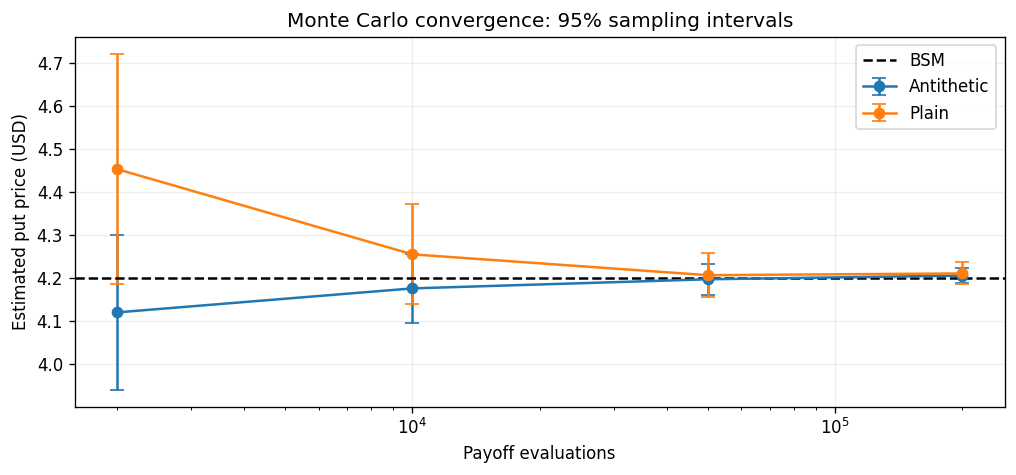

In [5]:
analytic=bsm_price(S,K,T,r,sigma,q,'put')
rows=[]
for n in [2000,10000,50000,200000]:
    for anti in [False,True]:
        result=mc_european(S,K,T,r,sigma,q,'put',n=n,seed=42,antithetic=anti)
        rows.append({'n':n,'method':'Antithetic' if anti else 'Plain',**result})
convergence=pd.DataFrame(rows);display(convergence)
for method,d in convergence.groupby('method'):
    plt.errorbar(d.n,d.price,yerr=1.96*d.SE,marker='o',capsize=4,label=method)
plt.axhline(analytic,color='black',linestyle='--',label='BSM')
plt.xscale('log');plt.xlabel('Payoff evaluations');plt.ylabel('Estimated put price (USD)');plt.title('Monte Carlo convergence: 95% sampling intervals');plt.legend();plt.show()
print('Intervals measure Monte Carlo sampling error only, not model or volatility-estimation uncertainty.')

PASS: put-call parity, Monte Carlo agreement and finite-difference delta
63-session volatility 15.65%; model put premium $4.199 (3.10% of spot).
Volatility-window premium range: $4.199–$5.674.


Assumed continuous rate,0.0,0.005,0.01,0.02
Volatility lookback,,,,
21,5.761353,5.674121,5.587773,5.417720
63,4.285938,4.199413,4.114045,3.946770
126,4.929589,4.842771,4.756970,4.588411
252,5.538489,5.451371,5.365169,5.195501


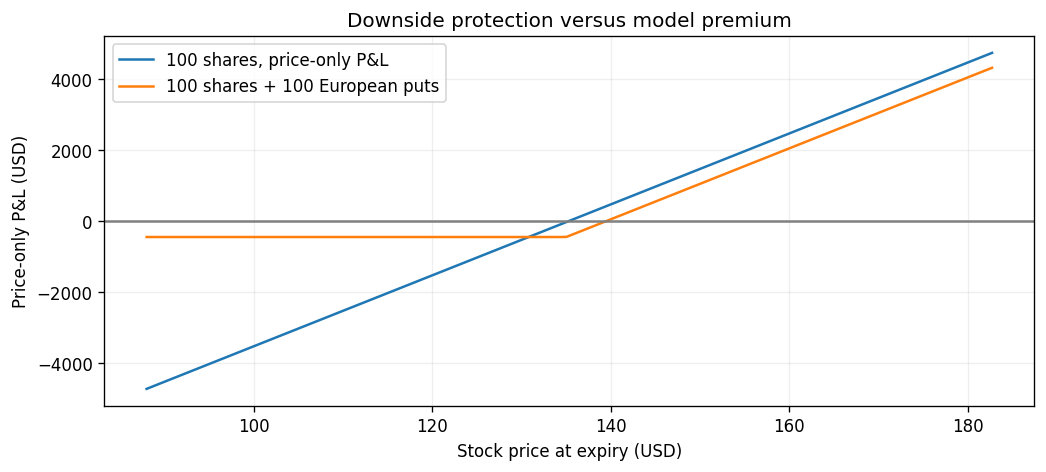

In [6]:
rate_grid=pd.DataFrame({rate:{n:bsm_price(S,K,T,rate,v,q,'put') for n,v in vols.items()} for rate in [0,.005,.01,.02]})
rate_grid.columns.name='Assumed continuous rate';rate_grid.index.name='Volatility lookback';display(rate_grid)
terminal=np.linspace(S*.65,S*1.35,150)
premium=analytic
# Price-only expiry P&L, premium financed at r. Dividends on stock omitted equally in both curves.
unhedged=100*(terminal-S)
hedged=unhedged+100*np.maximum(K-terminal,0)-100*premium*np.exp(r*T)
plt.plot(terminal,unhedged,label='100 shares, price-only P&L');plt.plot(terminal,hedged,label='100 shares + 100 European puts')
plt.axhline(0,color='gray');plt.xlabel('Stock price at expiry (USD)');plt.ylabel('Price-only P&L (USD)');plt.title('Downside protection versus model premium');plt.legend();plt.show()
call=bsm_price(S,K,T,r,sigma,q,'call')
assert abs(call-analytic-(S*np.exp(-q*T)-K*np.exp(-r*T)))<1e-9
mc=mc_european(S,K,T,r,sigma,q,'put',n=200000,seed=42,antithetic=True)
assert abs(mc['price']-analytic)<5*mc['SE']
h=.001
fd=(bsm_price(S+h,K,T,r,sigma,q,'put')-bsm_price(S-h,K,T,r,sigma,q,'put'))/(2*h)
assert abs(fd-greeks(S,K,T,r,sigma,q,'put')['delta'])<1e-6
print('PASS: put-call parity, Monte Carlo agreement and finite-difference delta')
print(f'63-session volatility {sigma:.2%}; model put premium ${analytic:.3f} ({analytic/S:.2%} of spot).')
print(f'Volatility-window premium range: ${valuation.put.min():.3f}–${valuation.put.max():.3f}.')

## Research conclusion
The hedge establishes a terminal price floor but incurs a premium. Window sensitivity is economically more meaningful than squeezing the Monte Carlo error to another decimal place: the assumed volatility determines the cost. BSM/Monte Carlo agreement validates the numerical implementation under shared assumptions; it does not prove that the model matches actual market quotes.

A trading extension needs timestamped option bid/ask quotes, contemporaneous rates, exact expiry calendars, discrete dividend forecasts and an American exercise model. Compare prices with midquotes and bid/ask spreads before alleging overpricing or underpricing. No implied-volatility estimate is reported here because no observed option premium was retrieved.